# QCNN (Macular Edema) 

This notebook trains the QCNN using three random seeds and
reports per-seed performance together with mean ± SD.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import random
import zipfile, os

# -------------------------------
BASE_MBR_DIR = "./data/mbrset"
EXTRACT_DIR = "./data/mbrset_images"

os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_list = [
    "training_mbrset.zip",
    "testing_mbrset.zip"
]

# ============================================================
# EXTRACT IMAGES
# ============================================================

for zname in zip_list:

    zpath = os.path.join(
        BASE_MBR_DIR,
        zname
    )

    print(f"Extracting: {zname}")

    with zipfile.ZipFile(zpath, "r") as z:
        z.extractall(EXTRACT_DIR)

print("All images extracted into:", EXTRACT_DIR)

# ============================================================
# LOAD LABELS
# ============================================================

CSV_PATH = os.path.join(
    BASE_MBR_DIR,
    "labels_mbrset.csv"
)

df = pd.read_csv(CSV_PATH)

print("Labels loaded:")

# Clean final_edema column safely
df["final_edema"] = (
    df["final_edema"]
    .replace(["Yes", "YES", "yes"], 1)
    .replace(["No", "NO", "no"], 0)
)

# Force invalid values to real NaN
df["final_edema"] = pd.to_numeric(df["final_edema"], errors="coerce")

# Drop invalid / missing labels
df = df.dropna(subset=["final_edema"])

# Convert to int
df["final_edema"] = df["final_edema"].astype(int)

print(df["final_edema"].value_counts())


def normalize_image_name(name):
    name = str(name).strip()
    if not name.lower().endswith((".jpg", ".jpeg", ".png")):
        name += ".jpg"
    return name.lower()

df["file"] = df["file"].apply(normalize_image_name)

import pathlib

image_dict = {
    p.name.lower(): str(p)
    for p in pathlib.Path(EXTRACT_DIR).rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("Total images found:", len(image_dict))

df["path"] = df["file"].map(image_dict)
df = df.dropna(subset=["path"])

x_all = df["path"].tolist()
y_all = df["final_edema"].tolist()

print("Usable samples:", len(x_all))

from sklearn.model_selection import StratifiedShuffleSplit
import numpy as np

from sklearn.model_selection import StratifiedShuffleSplit

# ============================================================
# 70% Train, 30% Temp
# ============================================================
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)

for train_idx, temp_idx in sss1.split(x_all, y_all):
    x_train = [x_all[i] for i in train_idx]
    y_train = [y_all[i] for i in train_idx]
    x_temp  = [x_all[i] for i in temp_idx]
    y_temp  = [y_all[i] for i in temp_idx]

# ============================================================
# Split temp (30%) → 10% Val, 20% Test
# That means: test_size = 20/30 = 0.6667
# ============================================================
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=2/3, random_state=42)

for val_idx, test_idx in sss2.split(x_temp, y_temp):
    x_val  = [x_temp[i] for i in val_idx]
    y_val  = [y_temp[i] for i in val_idx]
    x_test = [x_temp[i] for i in test_idx]
    y_test = [y_temp[i] for i in test_idx]

print(" Final split:")
print("Train:", len(x_train))  # ~70%
print("Val:  ", len(x_val))    # ~10%
print("Test: ", len(x_test))   # ~20%


print("\nLabel distribution:")
print("Train:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Val:  ", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test: ", dict(zip(*np.unique(y_test, return_counts=True))))

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

cw = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weights)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
num_classes = 2   # binary edema (0/1)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
])

def load_and_preprocess(path, label, augment=False):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)

    if augment:
        img = data_augmentation(img)

    img = preprocess_input(img)
    return img, tf.cast(label, tf.int32)

def make_dataset(paths, labels, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths))
    ds = ds.map(lambda x, y: load_and_preprocess(x, y, augment),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, augment=True, shuffle=True)
val_ds   = make_dataset(x_val,   y_val,   augment=False)
test_ds  = make_dataset(x_test,  y_test,  augment=False)



In [ ]:
train_set = set(x_train)
val_set   = set(x_val)
test_set  = set(x_test)

assert train_set.isdisjoint(val_set), "Train–Val overlap detected!"
assert train_set.isdisjoint(test_set), "Train–Test overlap detected!"
assert val_set.isdisjoint(test_set),   "Val–Test overlap detected!"

print(" Path-level check passed: no overlap between splits.")


In [ ]:
import hashlib
from tqdm import tqdm

def sha1(path, chunk_size=1 << 20):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print(" Hashing images (this may take a few minutes)...")

train_hashes = {sha1(p) for p in tqdm(x_train)}
val_hashes   = {sha1(p) for p in tqdm(x_val)}
test_hashes  = {sha1(p) for p in tqdm(x_test)}

assert train_hashes.isdisjoint(val_hashes), " Train–Val content overlap!"
assert train_hashes.isdisjoint(test_hashes), " Train–Test content overlap!"
assert val_hashes.isdisjoint(test_hashes),   " Val–Test content overlap!"

print(" Content-level check passed: no duplicate images across splits.")


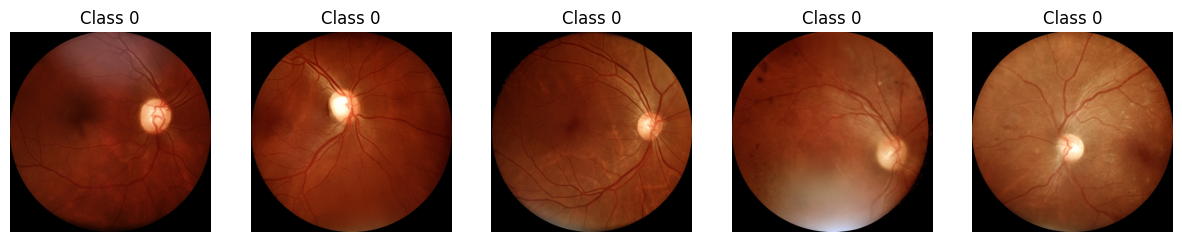

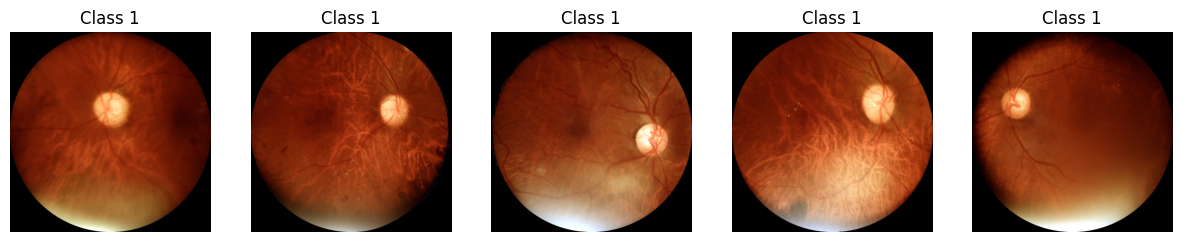

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

def show_examples_per_class(x_paths, y_labels, class_id, n=5):
    # Select paths for this class
    paths = [p for p, y in zip(x_paths, y_labels) if y == class_id]

    if len(paths) == 0:
        print(f"No images found for class {class_id}")
        return

    # Choose n random samples
    sample_paths = random.sample(paths, min(n, len(paths)))

    plt.figure(figsize=(15, 3))
    for i, p in enumerate(sample_paths):
        img = Image.open(p).convert("RGB")
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(f"Class {class_id}")
        plt.axis("off")
    plt.show()


# Show samples for both classes (0 and 1)
for cls in [0, 1]:
    show_examples_per_class(x_train, y_train, class_id=cls, n=5)


In [ ]:
# !pip install -q pennylane pennylane-lightning tqdm


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# ============================================================
#  Imports + Reproducibility
# ============================================================

import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import pennylane as qml
from pennylane.qnn import TorchLayer

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# ------------------------------------------------------------
# Seeds
# ------------------------------------------------------------

SEEDS = [42, 123, 456]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    os.environ["PYTHONHASHSEED"] = str(seed)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Seeds:", SEEDS)

Device: cuda
Seeds: [42, 123, 456]


In [ ]:
# ============================================================
#  Dataset + Transforms
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 12

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.1)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


class ImagePathDataset(Dataset):

    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        img = Image.open(
            self.paths[idx]
        ).convert("RGB")

        if self.transform:
            img = self.transform(img)

        return img, int(self.labels[idx])


train_ds = ImagePathDataset(
    x_train,
    y_train,
    transform=train_transform
)

val_ds = ImagePathDataset(
    x_val,
    y_val,
    transform=test_transform
)

test_ds = ImagePathDataset(
    x_test,
    y_test,
    transform=test_transform
)


# ============================================================
# Seed-specific DataLoaders
# ============================================================

def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)


def create_loaders(seed):

    generator = torch.Generator()

    generator.manual_seed(seed)

    _pin = torch.cuda.is_available()

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=_pin,
        persistent_workers=False,
        worker_init_fn=seed_worker,
        generator=generator
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=_pin,
        persistent_workers=False,
        worker_init_fn=seed_worker
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=_pin,
        persistent_workers=False,
        worker_init_fn=seed_worker
    )

    return (
        train_loader,
        val_loader,
        test_loader
    )
    
    

In [ ]:
# ============================================================
#  Hybrid QCNN Architecture
# ============================================================

n_qubits = 8
q_layers = 2

backbone_fc_dim = 512


def create_quantum_layer():

    # lightning.qubit: C++ backend, much faster than default.qubit,
    # and runs on CPU so it doesn't compete with GPU memory used by
    # the ResNet backbone.
    dev = qml.device(
        "lightning.qubit",
        wires=n_qubits
    )

    def qcnn_circuit(inputs, weights):

        inputs = torch.flatten(inputs)

        # --------------------------------------------
        # Data encoding
        # --------------------------------------------

        for i in range(n_qubits):
            qml.RY(
                inputs[i],
                wires=i
            )

        # --------------------------------------------
        # Variational layers
        # --------------------------------------------

        for l in range(q_layers):

            for i in range(n_qubits):

                qml.RX(
                    weights[l, i, 0],
                    wires=i
                )

                qml.RY(
                    weights[l, i, 1],
                    wires=i
                )

                qml.RZ(
                    weights[l, i, 2],
                    wires=i
                )

            # Even connections
            for i in range(
                0,
                n_qubits - 1,
                2
            ):
                qml.CNOT(
                    wires=[i, i + 1]
                )

            # Odd connections
            for i in range(
                1,
                n_qubits - 1,
                2
            ):
                qml.CNOT(
                    wires=[i, i + 1]
                )

        return [
            qml.expval(
                qml.PauliZ(i)
            )
            for i in range(n_qubits)
        ]

    weight_shapes = {
        "weights": (
            q_layers,
            n_qubits,
            3
        )
    }

    qnode = qml.QNode(
        qcnn_circuit,
        dev,
        interface="torch",
        diff_method="adjoint"
    )

    return TorchLayer(
        qnode,
        weight_shapes
    )


class HybridQCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # ------------------------------------------------
        # Fresh ResNet18 for each seed
        # ------------------------------------------------

        self.backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        # Freeze everything except layer4
        for name, param in self.backbone.named_parameters():

            if (
                "layer4" not in name
                and "fc" not in name
            ):
                param.requires_grad = False

        self.backbone.fc = nn.Identity()

        # ------------------------------------------------
        # Classical → quantum reduction
        # ------------------------------------------------

        self.reduce = nn.Linear(
            512,
            n_qubits
        )

        # ------------------------------------------------
        # Fresh quantum layer
        # ------------------------------------------------

        self.qlayer = create_quantum_layer()

        # ------------------------------------------------
        # Binary classifier
        # ------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                n_qubits,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        feats = self.backbone(x)

        angles = (
            torch.tanh(
                self.reduce(feats)
            )
            * (torch.pi / 2)
        )

        # Batched call: TorchLayer runs the whole batch through the
        # circuit in one vectorized pass instead of looping per-sample.
        # lightning.qubit runs this on CPU; move to CPU/back only if needed.
        q_outs = torch.stack([
            self.qlayer(a.unsqueeze(0).cpu()).squeeze(0)
            for a in angles
        ]).to(angles.device)

        return self.classifier(q_outs)
 
# ============================================================
#  Class Weight
# ============================================================

classes_np = np.array([0, 1])

class_wts = compute_class_weight(
    class_weight="balanced",
    classes=classes_np,
    y=y_train
)

pos_weight_value = (
    class_wts[1] /
    class_wts[0]
)

print(
    "Positive class weight:",
    pos_weight_value
)

# ============================================================
#  Training Function
# ============================================================

def run_one_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    train_flag=True
):

    if train_flag:
        model.train()
    else:
        model.eval()

    total = 0
    correct = 0
    total_loss = 0.0

    pbar = tqdm(
        loader,
        leave=False
    )

    for imgs, labels in pbar:

        imgs = imgs.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if train_flag:
            optimizer.zero_grad(
                set_to_none=True
            )

        with torch.set_grad_enabled(
            train_flag
        ):

            outputs = model(
                imgs
            ).squeeze(1)

            loss = criterion(
                outputs,
                labels.float()
            )

            if train_flag:

                loss.backward()

                optimizer.step()

        probs = torch.sigmoid(
            outputs
        )

        preds = (
            probs >= 0.5
        ).long()

        total_loss += (
            loss.item()
            * imgs.size(0)
        )

        correct += (
            preds == labels
        ).sum().item()

        total += imgs.size(0)

        pbar.set_postfix({
            "acc": correct / total,
            "loss": total_loss / total
        })

    return (
        total_loss / total,
        correct / total
    )    
    
    

Positive class weight: 10.464882943143811


In [ ]:
# ============================================================
#  Test Evaluation
# ============================================================

def evaluate_test(
    model,
    test_loader
):

    model.eval()

    all_probs = []
    all_preds = []
    all_true = []

    with torch.no_grad():

        for imgs, labels in test_loader:

            imgs = imgs.to(
                device,
                non_blocking=True
            )

            logits = model(
                imgs
            ).squeeze(1)

            probs = torch.sigmoid(
                logits
            )

            preds = (
                probs >= 0.5
            ).long()

            all_probs.extend(
                probs.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_true.extend(
                labels.numpy()
            )

    all_true = np.array(all_true)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    accuracy = accuracy_score(
        all_true,
        all_preds
    )

    f1 = f1_score(
        all_true,
        all_preds,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        all_true,
        all_probs
    )

    pr_auc = average_precision_score(
        all_true,
        all_probs
    )

    precision, recall, _ = precision_recall_curve(
        all_true,
        all_probs
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "y_true": all_true,
        "y_prob": all_probs,
        "y_pred": all_preds,
        "precision": precision,
        "recall": recall
    }

In [ ]:
# ============================================================
#  THREE-SEED QCNN EXPERIMENT
# ============================================================

import gc

all_results = []

for seed in SEEDS:

    print("\n")
    print("=" * 70)
    print(f" RUNNING QCNN — SEED {seed}")
    print("=" * 70)

    # --------------------------------------------------------
    # Set seed BEFORE model creation
    # --------------------------------------------------------

    set_seed(seed)

    # --------------------------------------------------------
    # Create seed-specific loaders
    # --------------------------------------------------------

    (
        train_loader,
        val_loader,
        test_loader
    ) = create_loaders(seed)

    # --------------------------------------------------------
    # Fresh model
    # --------------------------------------------------------

    model = HybridQCNN().to(device)

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    pos_weight = torch.tensor(
        pos_weight_value,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight
    )

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        factor=0.5,
        patience=3
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    best_val = 0.0
    stale = 0

    patience = 5

    checkpoint_path = (
        f"best_qcnn_binary_seed_{seed}.pth"
    )

    for epoch in range(1, 10):

        print(
            f"\nSeed {seed} | Epoch {epoch}"
        )

        train_loss, train_acc = run_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            train_flag=True
        )

        val_loss, val_acc = run_one_epoch(
            model,
            val_loader,
            criterion,
            optimizer=None,
            train_flag=False
        )

        scheduler.step(val_loss)

        print(
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        # ----------------------------------------------------
        # Save best model
        # ----------------------------------------------------

        if val_acc > best_val:

            best_val = val_acc

            stale = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print(
                f" Saved {checkpoint_path}"
            )

        else:

            stale += 1

        if stale >= patience:

            print(
                " Early stopping"
            )

            break

    # --------------------------------------------------------
    # Load best checkpoint
    # --------------------------------------------------------

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------

    results = evaluate_test(
        model,
        test_loader
    )

    # --------------------------------------------------------
    # Store metrics
    # --------------------------------------------------------

    all_results.append({

        "seed": seed,

        "best_val_accuracy":
            best_val,

        "test_accuracy":
            results["accuracy"],

        "f1":
            results["f1"],

        "roc_auc":
            results["roc_auc"],

        "pr_auc":
            results["pr_auc"]
    })

    # --------------------------------------------------------
    # Save PR data for this seed
    # --------------------------------------------------------

    np.savez(
        f"qcnn_pr_seed_{seed}.npz",

        y_true=results["y_true"],

        y_prob=results["y_prob"],

        precision=results["precision"],

        recall=results["recall"]
    )

    print("\n")
    print(
        f"Seed {seed} Results"
    )
    print(
        f"Accuracy : {results['accuracy']:.4f}"
    )
    print(
        f"F1       : {results['f1']:.4f}"
    )
    print(
        f"ROC-AUC  : {results['roc_auc']:.4f}"
    )
    print(
        f"PR-AUC   : {results['pr_auc']:.4f}"
    )

    

    del model, optimizer, scheduler
    del train_loader, val_loader, test_loader
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
# ============================================================
#  MEAN ± SD ACROSS 3 SEEDS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 70)
print(" THREE-SEED RESULTS")
print("=" * 70)

print(
    results_df.to_string(
        index=False
    )
)


metrics = [
    "test_accuracy",
    "f1",
    "roc_auc",
    "pr_auc"
]

summary = []

for metric in metrics:

    mean_value = results_df[
        metric
    ].mean()

    std_value = results_df[
        metric
    ].std(ddof=1)

    summary.append({

        "Metric": metric,

        "Mean": mean_value,

        "SD": std_value,

        "Mean ± SD":
            f"{mean_value:.4f} ± {std_value:.4f}"
    })


summary_df = pd.DataFrame(
    summary
)

print("\n")
print("=" * 70)
print(" FINAL QCNN RESULTS — MEAN ± SD")
print("=" * 70)

print(
    summary_df.to_string(
        index=False
    )
)

# Save results
results_df.to_csv(
    "qcnn_three_seed_results.csv",
    index=False
)

summary_df.to_csv(
    "qcnn_three_seed_summary.csv",
    index=False
)    



🔥 RUNNING QCNN — SEED 42

Seed 42 | Epoch 1


Train Acc: 0.7914 | Val Acc: 0.8959
✅ Saved best_qcnn_binary_seed_42.pth

Seed 42 | Epoch 2


Train Acc: 0.8320 | Val Acc: 0.9061
✅ Saved best_qcnn_binary_seed_42.pth

Seed 42 | Epoch 3


Train Acc: 0.7935 | Val Acc: 0.9306
✅ Saved best_qcnn_binary_seed_42.pth

Seed 42 | Epoch 4


Train Acc: 0.8162 | Val Acc: 0.9388
✅ Saved best_qcnn_binary_seed_42.pth

Seed 42 | Epoch 5


...

Train Acc: 0.7634 | Val Acc: 0.8714

Seed 456 | Epoch 6


Train Acc: 0.8005 | Val Acc: 0.8918
✅ Saved best_qcnn_binary_seed_456.pth

Seed 456 | Epoch 7


Train Acc: 0.8139 | Val Acc: 0.9347
✅ Saved best_qcnn_binary_seed_456.pth

Seed 456 | Epoch 8


Train Acc: 0.8165 | Val Acc: 0.9408
✅ Saved best_qcnn_binary_seed_456.pth

Seed 456 | Epoch 9


Train Acc: 0.8276 | Val Acc: 0.9408


Seed 456 Results
Accuracy : 0.9061
F1       : 0.5400
ROC-AUC  : 0.8515
PR-AUC   : 0.4881


📊 THREE-SEED RESULTS
 seed  best_val_accuracy  test_accuracy       f1  roc_auc   pr_auc
   42           0.938776       0.937755 0.630303 0.800605 0.502819
  123           0.948980       0.922449 0.552941 0.813934 0.526443
  456           0.940816       0.906122 0.540000 0.851515 0.488055


📊 FINAL QCNN RESULTS — MEAN ± SD
       Metric     Mean       SD       Mean ± SD
test_accuracy 0.922109 0.015819 0.9221 ± 0.0158
           f1 0.574415 0.048831 0.5744 ± 0.0488
      roc_auc 0.822018 0.026400 0.8220 ± 0.0264
       pr_auc 0.505772 0.019364 0.5058 ± 0.0194


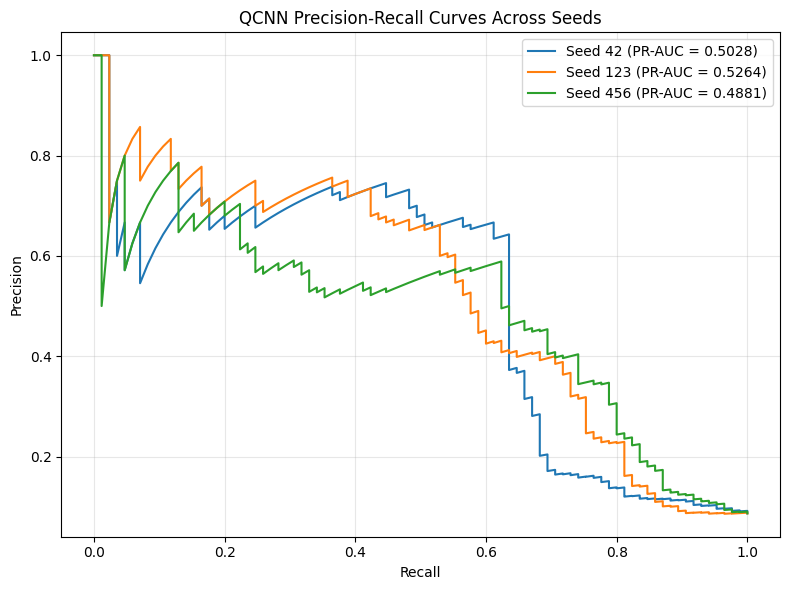

In [ ]:
# ============================================================
# PR CURVES — ALL 3 SEEDS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for seed in SEEDS:

    data = np.load(
        f"qcnn_pr_seed_{seed}.npz"
    )

    precision = data["precision"]
    recall = data["recall"]

    pr_auc = average_precision_score(
        data["y_true"],
        data["y_prob"]
    )

    plt.plot(
        recall,
        precision,
        label=f"Seed {seed} (PR-AUC = {pr_auc:.4f})"
    )


plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "QCNN Precision-Recall Curves Across Seeds"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "qcnn_pr_curves_three_seeds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



📊 CLASSIFICATION REPORT — SEED 42
              precision    recall  f1-score   support

    No Edema     0.9633    0.9687    0.9660       895
       Edema     0.6500    0.6118    0.6303        85

    accuracy                         0.9378       980
   macro avg     0.8067    0.7902    0.7982       980
weighted avg     0.9362    0.9378    0.9369       980

Confusion Matrix:
[[867  28]
 [ 33  52]]


📊 CLASSIFICATION REPORT — SEED 123
              precision    recall  f1-score   support

    No Edema     0.9575    0.9575    0.9575       895
       Edema     0.5529    0.5529    0.5529        85

    accuracy                         0.9224       980
   macro avg     0.7552    0.7552    0.7552       980
weighted avg     0.9224    0.9224    0.9224       980

Confusion Matrix:
[[857  38]
 [ 38  47]]


📊 CLASSIFICATION REPORT — SEED 456
              precision    recall  f1-score   support

    No Edema     0.9642    0.9318    0.9477       895
       Edema     0.4696    0.6353    0.5400  

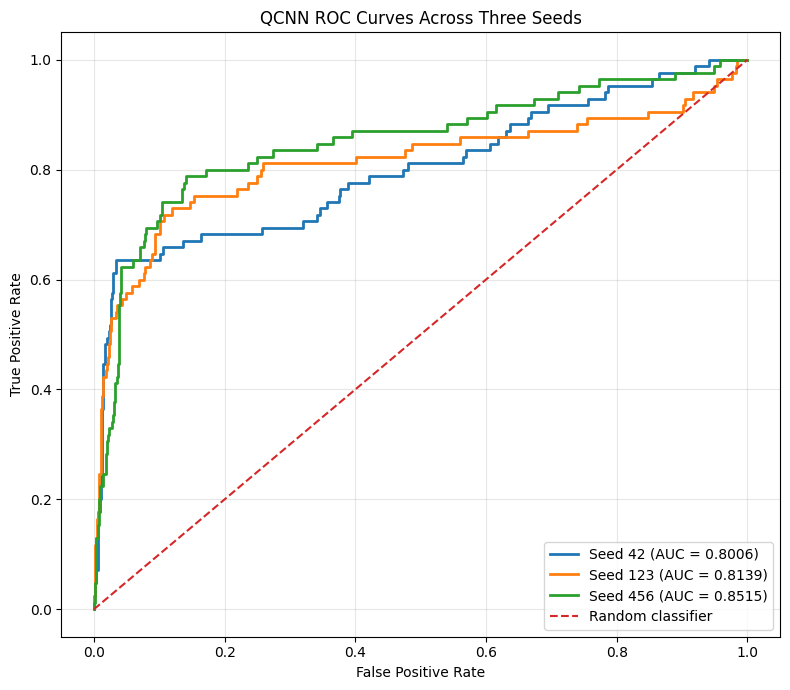



📊 ROC-AUC ACROSS THREE SEEDS
Seed 42: 0.8006
Seed 123: 0.8139
Seed 456: 0.8515

Mean ROC-AUC: 0.8220
SD ROC-AUC: 0.0264
ROC-AUC: 0.8220 ± 0.0264


In [ ]:
# ============================================================
#  THREE-SEED CLASSIFICATION REPORTS + ROC CURVES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# Seeds
# ------------------------------------------------------------

SEEDS = [42, 123, 456]

all_seed_reports = []
roc_data = {}

# ------------------------------------------------------------
# Process each seed
# ------------------------------------------------------------

for seed in SEEDS:

    file_path = f"qcnn_pr_seed_{seed}.npz"

    if not os.path.exists(file_path):

        print(
            f" File not found: {file_path}"
        )

        continue

    data = np.load(file_path)

    y_true = data["y_true"]
    y_prob = data["y_prob"]

    # --------------------------------------------------------
    # Predictions at threshold = 0.5
    # --------------------------------------------------------

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=[
            "No Edema",
            "Edema"
        ],
        digits=4,
        zero_division=0
    )

    print("\n")
    print("=" * 70)
    print(f" CLASSIFICATION REPORT — SEED {seed}")
    print("=" * 70)
    print(report)

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    print(
        "Confusion Matrix:"
    )

    print(cm)

    # --------------------------------------------------------
    # Extract useful metrics
    # --------------------------------------------------------

    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=[
            "No Edema",
            "Edema"
        ],
        output_dict=True,
        zero_division=0
    )

    all_seed_reports.append({

        "Seed": seed,

        "Accuracy":
            report_dict["accuracy"],

        "No Edema Precision":
            report_dict["No Edema"]["precision"],

        "No Edema Recall":
            report_dict["No Edema"]["recall"],

        "No Edema F1":
            report_dict["No Edema"]["f1-score"],

        "Edema Precision":
            report_dict["Edema"]["precision"],

        "Edema Recall":
            report_dict["Edema"]["recall"],

        "Edema F1":
            report_dict["Edema"]["f1-score"],

        "Macro F1":
            report_dict["macro avg"]["f1-score"],

        "Weighted F1":
            report_dict["weighted avg"]["f1-score"],

        "ROC-AUC":
            roc_auc_score(
                y_true,
                y_prob
            )
    })

    # --------------------------------------------------------
    # ROC curve
    # --------------------------------------------------------

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    roc_data[seed] = {

        "fpr": fpr,

        "tpr": tpr,

        "auc": roc_auc
    }


# ============================================================
#  CLASSIFICATION REPORT SUMMARY
# ============================================================

classification_df = pd.DataFrame(
    all_seed_reports
)

print("\n")
print("=" * 70)
print(" CLASSIFICATION REPORT SUMMARY")
print("=" * 70)

print(
    classification_df.to_string(
        index=False
    )
)

classification_df.to_csv(
    "qcnn_three_seed_classification_summary.csv",
    index=False
)


# ============================================================
#  COMBINED ROC CURVE
# ============================================================

plt.figure(
    figsize=(8, 7)
)

for seed in SEEDS:

    if seed not in roc_data:
        continue

    plt.plot(
        roc_data[seed]["fpr"],
        roc_data[seed]["tpr"],
        linewidth=2,
        label=(
            f"Seed {seed} "
            f"(AUC = {roc_data[seed]['auc']:.4f})"
        )
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "QCNN ROC Curves Across Three Seeds"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "qcnn_three_seed_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
#  ROC-AUC MEAN ± SD
# ============================================================

auc_values = [
    roc_data[seed]["auc"]
    for seed in SEEDS
    if seed in roc_data
]

auc_mean = np.mean(
    auc_values
)

auc_sd = np.std(
    auc_values,
    ddof=1
)

print("\n")
print("=" * 70)
print(" ROC-AUC ACROSS THREE SEEDS")
print("=" * 70)

for seed in SEEDS:

    if seed in roc_data:

        print(
            f"Seed {seed}: "
            f"{roc_data[seed]['auc']:.4f}"
        )

print(
    f"\nMean ROC-AUC: "
    f"{auc_mean:.4f}"
)

print(
    f"SD ROC-AUC: "
    f"{auc_sd:.4f}"
)

print(
    f"ROC-AUC: "
    f"{auc_mean:.4f} ± {auc_sd:.4f}"
)